### récuperation des catégories emotions

In [6]:
with open("/home/aguerouani/free-gen-playlist/Data/archive/dataset/categories.txt", "r", encoding="utf-8") as f:
    # Lire toutes les lignes, enlever les sauts de ligne
    genres = [line.strip() for line in f]

# Vérification
print(genres[:20])  # Affiche les 20 premiers pour vérifier
print(f"Nombre total de genres : {len(genres)}")

['Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous']
Nombre total de genres : 903


### Embedding extraction

In [7]:
import torch
import librosa
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from muq import MuQ


In [ ]:
from embeddings.embedding_extraction import extract_embedding
data_dir = 'Data/archive/dataset/Audio'
embeddings = []
filenames = []
file_genres = []

import os
import re
import numpy as np
import pandas as pd
import torch

mp3_entries = []
for root, _, files in os.walk(data_dir):
    for f in files:
        if f.lower().endswith('.mp3'):
            full_path = os.path.join(root, f)
            
            current_dir = os.path.basename(root)                 
            parent_dir = os.path.basename(os.path.dirname(root)) 
            
            
            genre = parent_dir
            
            mp3_entries.append((full_path, f, genre))

# Trier par numéro en tête du nom de fichier si présent (1.mp3, 2.mp3 ...)
def leading_num(fname):
    m = re.match(r'^(\d+)', fname)
    return int(m.group(1)) if m else float('inf')

mp3_entries.sort(key=lambda x: leading_num(x[1]))

# Extraction des embeddings
for full_path, fname, genre in mp3_entries:
    emb = extract_embedding(full_path)
    if emb is None:
        continue
    embeddings.append(emb)
    filenames.append(fname)
    file_genres.append(genre)
    print(f"✅ Fichier traité : {fname} | Genre (dossier) : {genre} | Embedding : {emb.shape}")

# --- Sauvegarde ---
embeddings = np.array(embeddings)
df = pd.DataFrame(embeddings)
df['genre'] = file_genres
df['filename'] = filenames

df.to_csv("muq_embedding_MIREX.csv", index=False)
torch.save({'embeddings': torch.tensor(embeddings), 'genres': file_genres, 'filenames': filenames}, "muq_embeddings.pt")

print("✅ Extraction terminée !")
print("Dimensions embeddings :", embeddings.shape)  # (N, D)

✅ Fichier traité : 001.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 002.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 003.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 004.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 005.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 006.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 007.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 008.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 009.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 010.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 011.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 012.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 013.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fichier traité : 014.mp3 | Genre (dossier) : 1 | Embedding : (1024,)
✅ Fich

### Visualisation

Loaded embeddings shape: (903, 1024)
t-SNE result shape: (903, 2)
✅ t-SNE plot saved as tsne_muQ_embeddings_FMA.png


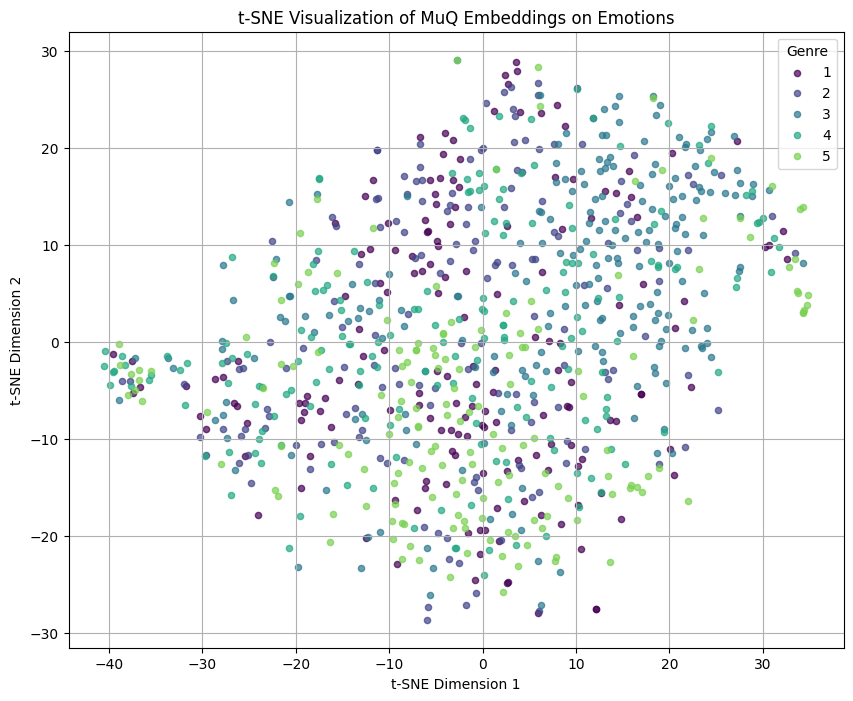

In [11]:
from tsne_vis import load_embeddings
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np



embeddings , genres , filenames = load_embeddings("muq_embedding_MIREX.csv")
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)
plt.figure(figsize=(10, 8))
# Obtenir la liste unique des genres
unique_genres = np.unique(genres)
n_classes = len(unique_genres)

cmap = plt.get_cmap("viridis")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_genres)}
# Plot genre par genre
for genre in unique_genres:
    idx = genres == genre
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=genre, color=class_to_color[genre], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Emotions")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Genre")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("tsne_muQ_embeddings_MIREX.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_embeddings_FMA.png")